# Top-level comments: exploratory analysis

A top-level comment replies directly to the submission (its `parent_id` starts with `t3_`); every other comment is a reply to another comment (`t1_`). This notebook looks only at top-level comments.

## 1. Setup and loading

In [1]:
import html
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.core.error import StdinNotImplementedError
from IPython.display import clear_output

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "data").exists():
    raise FileNotFoundError("Could not find project root with data/ directory.")

CLEAN = ROOT / "data" / "cleaned"
COMMENTS_PATH = CLEAN / "comments_clean.parquet"
SUBMISSIONS_PATH = CLEAN / "submissions_clean.parquet"

PERIODS = ["T1_Y1", "T1_Y2", "T2_Y1", "T2_Y2"]
SUBREDDITS = ["politics", "AskTrumpSupporters", "Conservative", "PoliticalDiscussion", "democrats", "Republican"]

The comments table has about 4.5M rows, so it is read without the text columns `body` and `body_clean`.

In [2]:
comments_file = pq.ParquetFile(COMMENTS_PATH)
TEXT_COLUMNS = ["body", "body_clean"]
light_columns = [c for c in comments_file.schema_arrow.names if c not in TEXT_COLUMNS]
com = pd.read_parquet(COMMENTS_PATH, columns=light_columns)
com.shape

(4514780, 24)

## 2. Selecting top-level comments

In [3]:
# is_top_level is set in reddit_cleaning.ipynb; check it against parent_id before using it
assert (com["is_top_level"] == com["parent_id"].str.startswith("t3_")).all()

top = com[com["is_top_level"]].reset_index(drop=True)

n_all, n_top = len(com), len(top)
print(f"All comments:       {n_all:,}")
print(f"Top-level comments: {n_top:,} ({n_top / n_all:.1%} of all comments)")

All comments:       4,514,780
Top-level comments: 1,397,476 (31.0% of all comments)


## 3. Manual labels

**Goal.** Both of us label the same 500 top-level comments by hand. Comparing the two sets of labels later shows how often two people disagree about the stance of a comment.

### 3.1 Sample

Rules of the draw:

- `"Trump"` is in the comment's own text and not only in a quote, and the comment is between `MIN_WORDS` and `MAX_WORDS` words long.
- The post of the thread is in `submissions_clean.parquet`, so it can be shown next to the comment.
- The same number of comments comes from each of the six subreddits, and inside a subreddit from each of the four windows (the same rule as section 1.1 of `model_selection.ipynb`). Otherwise r/politics would give almost all of the sample.
- The sample is saved to `data/top_comments/label_sample.csv` and read from there on every later run. `data/` is not shared between our computers, so the second annotator copies this file instead of drawing the sample again.

In [4]:
LABEL_DIR = ROOT / "data" / "top_comments"
LABEL_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_PATH = LABEL_DIR / "label_sample.csv"

N_SAMPLE = 500                # comments in the sample; both annotators label all of them
MIN_WORDS, MAX_WORDS = 5, 250 # length limits of a comment, in words
OVERSAMPLE = 60               # candidates drawn per subreddit and window before their text is checked
SEED = 42
REBUILD_SAMPLE = False        # True draws a new sample and overwrites the file; labels of replaced comments no longer apply


def quotas(total, groups, offset=0):
    """Split `total` as evenly as possible over `groups`. The remainder goes to the groups starting at position `offset`."""
    base, extra = divmod(total, len(groups))
    return {g: base + ((i - offset) % len(groups) < extra) for i, g in enumerate(groups)}


def stratified(pool, total):
    """`total` rows of a shuffled `pool`: equal numbers per subreddit, then equal numbers per window inside a subreddit."""
    by_size = list(pool["subreddit"].value_counts().index)     # a remainder goes to the subreddits with the most eligible comments
    picked = []
    for i, (s, n_subreddit) in enumerate(quotas(total, by_size).items()):
        for p, n in quotas(n_subreddit, PERIODS, offset=i).items():
            stratum = pool.loc[(pool["subreddit"] == s) & (pool["period"] == p)].head(n)
            assert len(stratum) == n, f"not enough comments in r/{s}, {p}"
            picked.append(stratum)
    return pd.concat(picked)


def draw_sample():
    # candidates are chosen from the metadata, and the text is read only for them
    pool = top.loc[~top["trump_only_in_quote"], ["id", "submission_id", "subreddit", "period"]]
    candidates = pool.groupby(["subreddit", "period"]).sample(n=OVERSAMPLE, random_state=SEED)
    comments = pq.read_table(COMMENTS_PATH, columns=["id", "body_clean"],
                             filters=[("id", "in", candidates["id"].tolist())]).to_pandas()
    posts = pq.read_table(SUBMISSIONS_PATH, columns=["id", "title", "selftext", "domain"],
                          filters=[("id", "in", candidates["submission_id"].unique().tolist())]).to_pandas()
    posts.columns = ["submission_id", "post_title", "post_body", "post_domain"]

    rows = (candidates
            .merge(comments.rename(columns={"body_clean": "comment"}), on="id", validate="one_to_one")
            .merge(posts, on="submission_id", validate="many_to_one"))     # comments whose post is missing are dropped
    rows = rows.loc[rows["comment"].str.count(r"\S+").between(MIN_WORDS, MAX_WORDS)
                    & rows["comment"].str.contains("trump", case=False)]

    out = stratified(rows.sample(frac=1, random_state=SEED), N_SAMPLE).sample(frac=1, random_state=SEED)
    out["order"] = np.arange(1, len(out) + 1)                  # reading order, the same for both annotators
    assert out["id"].is_unique
    return out[["id", "submission_id", "subreddit", "period", "order", "post_title", "post_domain", "post_body", "comment"]]


if REBUILD_SAMPLE or not SAMPLE_PATH.exists():
    draw_sample().to_csv(SAMPLE_PATH, index=False, lineterminator="\n")
sample = pd.read_csv(SAMPLE_PATH, dtype=str, keep_default_na=False)    # an empty post body stays an empty string
sample["order"] = sample["order"].astype(int)

composition = pd.crosstab(sample["subreddit"], sample["period"]).reindex(index=SUBREDDITS, columns=PERIODS)
composition["all"] = composition.sum(axis=1)
composition.loc["All"] = composition.sum()
print(f"{len(sample)} comments, median {sample['comment'].str.count(r'\S+').median():.0f} words")
composition

500 comments, median 46 words


period,T1_Y1,T1_Y2,T2_Y1,T2_Y2,all
subreddit,,,,,
politics,21,21,20,21,83
AskTrumpSupporters,21,21,21,20,83
Conservative,21,21,21,21,84
PoliticalDiscussion,20,21,21,21,83
democrats,21,20,21,21,83
Republican,21,21,21,21,84
All,125,125,125,125,500


### 3.2 Labelling

Each of us runs the cell with our own number. The cell shows one comment at a time together with the post of its thread and asks for a label. The subreddit, the window, the author's flair and the model's prediction are hidden, so they do not influence the label.

**What to label:** the attitude of the comment's author toward Trump or his decisions, as far as the comment shows it.

| Key | Label | When |
|---|---|---|
| `a` | `against` | The author criticises, mocks or opposes Trump, his decisions or his administration |
| `n` | `neutral` | No clear attitude: a question, a fact, or a comment about something else that only mentions Trump |
| `p` | `pro` | The author supports, defends or praises Trump or his decisions |
| `s` | skip | The comment cannot be judged (not readable, not in English). Skipped comments are left out of the comparison |

The labels are the same three classes as `student_label`, so they can also be compared with the model later.

Rules for the hard cases, so that both of us decide the same way:

- The post is context only. Use it to understand what the comment answers (for example, sarcasm aimed at the headline), but label the attitude of the comment's author, not of the post.
- Sarcasm and irony are labelled by what the author means, not by the words.
- An attack on Trump's opponents or on the media is `pro` only when the defence of Trump is clear. Otherwise it is `neutral`.
- A comment that criticises one decision and supports Trump in general (or the opposite) gets the label of its main point.
- A quote of Trump with no comment from the author is `neutral`.

Controls: `b` goes back one comment, `q` stops. Every answer is saved at once to `data/top_comments/labels_annotator1.csv` or `labels_annotator2.csv`, and running the cell again continues from the first comment without a label.

In [5]:
KEYS = {"a": "against", "n": "neutral", "p": "pro", "s": "skip"}
LINE_WIDTH = 110        # characters per line when a text is shown
MAX_POST_CHARS = 1500   # a longer post body is cut; the comment is always shown in full


def labels_path(annotator):
    return LABEL_DIR / f"labels_annotator{annotator}.csv"


def load_labels(annotator):
    path = labels_path(annotator)
    if not path.exists():
        return {}
    saved = pd.read_csv(path, dtype=str)
    unknown = set(saved["id"]) - set(sample["id"])
    assert not unknown, f"{path.name} has {len(unknown)} comments that are not in the sample; was the sample drawn again?"
    return dict(saved[["id", "label"]].to_numpy())


def save_labels(annotator, done):
    path = labels_path(annotator)
    tmp = path.with_suffix(".tmp")
    pd.DataFrame(list(done.items()), columns=["id", "label"]).to_csv(tmp, index=False, lineterminator="\n")
    tmp.replace(path)                                          # an interrupted save cannot leave a half-written file


def wrap(text):
    text = html.unescape(text)                                 # the raw post text keeps &amp;, &gt; and similar
    return "\n".join(textwrap.fill(line, LINE_WIDTH) for line in text.splitlines())


def show(row, header):
    clear_output(wait=True)
    print(header + "\n")
    print("POST\n")
    print(wrap(row["post_title"]))
    if not row["post_domain"].startswith("self."):
        print(f"(link to {row['post_domain']})")
    if row["post_body"]:
        body = row["post_body"]
        print("\n" + wrap(body[:MAX_POST_CHARS] + (" [...]" if len(body) > MAX_POST_CHARS else "")))
    print("\n" + "-" * LINE_WIDTH + "\nCOMMENT\n")
    print(wrap(row["comment"]))


def annotate(annotator):
    """Show the sample comments one by one and ask for a label. The answers are saved after every comment."""
    rows = sample.sort_values("order").reset_index(drop=True)
    done = load_labels(annotator)
    i = next((k for k, comment_id in enumerate(rows["id"]) if comment_id not in done), len(rows))
    try:
        while i < len(rows):
            row = rows.loc[i]
            show(row, f"Annotator {annotator} | comment {i + 1} of {len(rows)} | {len(done)} labelled")
            current = f" (now: {done[row['id']]}, Enter keeps it)" if row["id"] in done else ""
            answer = input(f"\n[a] against  [n] neutral  [p] pro  [s] skip  [b] back  [q] stop{current} > ").strip().lower()
            if answer == "q":
                break
            if answer == "b":
                i = max(i - 1, 0)
            elif answer in KEYS:
                done[row["id"]] = KEYS[answer]
                save_labels(annotator, done)
                i += 1
            elif answer == "" and current:
                i += 1
    except (StdinNotImplementedError, KeyboardInterrupt):
        pass                                                   # no keyboard input (for example during an export)
    clear_output(wait=True)
    print(f"Annotator {annotator}: {len(done)} of {len(rows)} comments are labelled"
          + ("" if len(done) == len(rows) else "; run this cell to continue"))

**Annotator 1**

In [6]:
# annotate(annotator=1)

**Annotator 2**

In [7]:
# annotate(annotator=2)

### 3.3 Agreement between the annotators

The comparison uses the comments that both of us labelled and neither skipped. The measures:

- **Observed agreement**: the share of comments with the same label from both annotators.
- **Cohen's kappa**: the agreement above what two annotators would reach by chance if they used the labels as often as they did. 0 is chance level, 1 is full agreement.
- **Weighted kappa** (linear weights): the labels are ordered `against` < `neutral` < `pro`, so `against` vs `pro` counts as a bigger disagreement than either of them vs `neutral`.
- **Against vs pro**: the share of comments that one annotator called `against` and the other `pro`.
- **Same direction**: among the comments that neither annotator called `neutral`, the share with the same direction.

The 95% intervals come from a bootstrap over comments (`N_BOOT` resamples).

In [8]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

CLASSES = ["against", "neutral", "pro"]
LABEL_COLOR = {"against": "#2878B5", "neutral": "#B9BEC6", "pro": "#D64550"}   # the same colours as in eda.ipynb
INK, INK_2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
N_BOOT = 2000           # bootstrap resamples for the confidence intervals

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 10, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlesize": 10, "axes.titlelocation": "left", "axes.titlecolor": INK_2,
    "axes.labelsize": 9.5, "axes.labelcolor": INK_2,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
})

both = sample.copy()
for a in (1, 2):
    saved = pd.read_csv(labels_path(a), dtype=str)
    assert set(saved["id"]) == set(sample["id"]), f"annotator {a} has not labelled the whole sample yet"
    both = both.merge(saved.rename(columns={"label": f"label_{a}"}), on="id", validate="one_to_one")

skipped = both["label_1"].eq("skip") | both["label_2"].eq("skip")
pairs = both.loc[~skipped].reset_index(drop=True)
pairs["words"] = pairs["comment"].str.count(r"\S+")
codes = np.column_stack([pairs[f"label_{a}"].map(CLASSES.index).to_numpy() for a in (1, 2)])   # 0 against, 1 neutral, 2 pro
print(f"{len(pairs)} comments labelled by both annotators; {skipped.sum()} skipped by at least one of them and left out")


def confusion(c):
    """3 x 3 counts: rows are annotator 1, columns annotator 2."""
    return np.bincount(c[:, 0] * 3 + c[:, 1], minlength=9).reshape(3, 3)


def kappa(m, weights=None):
    """Cohen's kappa from a confusion matrix. weights="linear" counts against vs pro as twice the disagreement of either vs neutral."""
    w = np.abs(np.subtract.outer(np.arange(3), np.arange(3))) / 2 if weights == "linear" else 1 - np.eye(3)
    p = m / m.sum()
    expected = np.outer(p.sum(axis=1), p.sum(axis=0))
    return 1 - (w * p).sum() / (w * expected).sum()


def measures(m):
    polar = m[np.ix_([0, 2], [0, 2])]                          # both annotators gave a direction
    return {
        "comments": m.sum(),
        "agreement": np.trace(m) / m.sum(),
        "cohen_kappa": kappa(m),
        "weighted_kappa": kappa(m, "linear"),
        "against_vs_pro": (m[0, 2] + m[2, 0]) / m.sum(),         # share of comments with opposite labels
        "same_direction": np.trace(polar) / polar.sum(),         # agreement among comments neither annotator called neutral
    }


def bootstrap(c, rng):
    """Measures on `N_BOOT` resamples of the comments."""
    rows = rng.integers(0, len(c), size=(N_BOOT, len(c)))
    return pd.DataFrame([measures(confusion(c[r])) for r in rows])


rng = np.random.default_rng(SEED)
m_all = confusion(codes)
boot = bootstrap(codes, rng)
summary = pd.DataFrame({"value": measures(m_all), "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)})
summary.loc["comments", ["ci_low", "ci_high"]] = np.nan
summary.round(3)

500 comments labelled by both annotators; 0 skipped by at least one of them and left out


,value,ci_low,ci_high
comments,500.000,NaN,NaN
agreement,0.766,0.728,0.800
cohen_kappa,0.646,0.592,0.697
weighted_kappa,0.712,0.662,0.758
against_vs_pro,0.026,0.014,0.040
same_direction,0.957,0.933,0.977


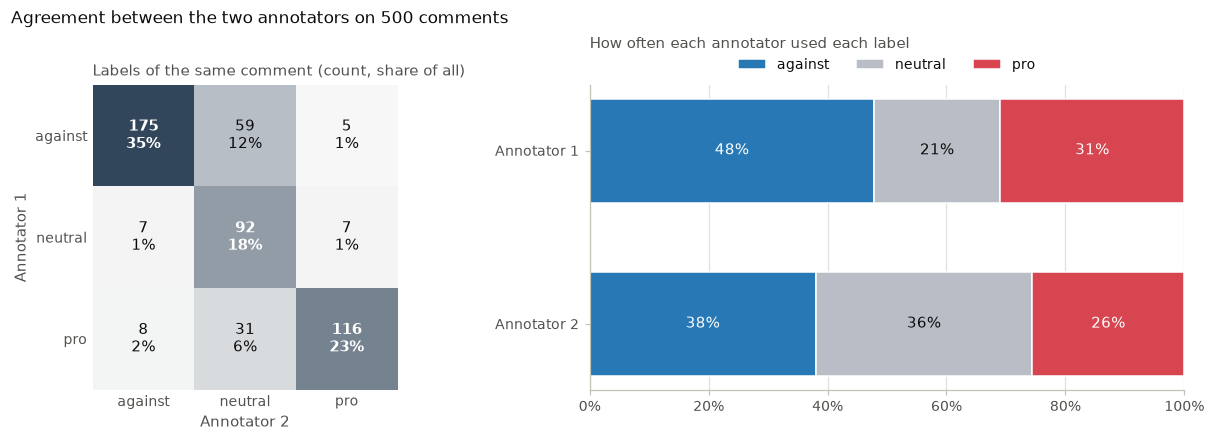

In [9]:
fig, (ax_m, ax_d) = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1, 1.25]}, layout="constrained")

ax_m.imshow(m_all / m_all.sum(), cmap=mcolors.LinearSegmentedColormap.from_list("magnitude", ["#F7F7F7", "#31465A"]))
for i in range(3):
    for j in range(3):
        share = m_all[i, j] / m_all.sum()
        ax_m.text(j, i, f"{m_all[i, j]}\n{share:.0%}", ha="center", va="center", fontsize=9.5,
                  color="white" if share > 0.15 else INK, fontweight="bold" if i == j else "normal")
ax_m.set_xticks(range(3), CLASSES)
ax_m.set_yticks(range(3), CLASSES)
ax_m.set_xlabel("Annotator 2")
ax_m.set_ylabel("Annotator 1")
ax_m.grid(False)
ax_m.tick_params(length=0)
for side in ax_m.spines.values():
    side.set_visible(False)
ax_m.set_title("Labels of the same comment (count, share of all)")

dist = pd.DataFrame({a: pairs[f"label_{a}"].value_counts(normalize=True).reindex(CLASSES, fill_value=0) for a in (1, 2)})
left = np.zeros(2)
for label in CLASSES:
    share = dist.loc[label].to_numpy()
    ax_d.barh([1, 0], share, left=left, height=0.6, color=LABEL_COLOR[label], edgecolor="white", label=label)
    for y, s, l in zip([1, 0], share, left):
        ax_d.text(l + s / 2, y, f"{s:.0%}", ha="center", va="center", fontsize=9.5, color=INK if label == "neutral" else "white")
    left += share
ax_d.set_yticks([1, 0], ["Annotator 1", "Annotator 2"])
ax_d.set_xlim(0, 1)
ax_d.xaxis.set_major_formatter(mticker.PercentFormatter(1))
ax_d.grid(axis="y", visible=False)
ax_d.legend(ncols=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax_d.set_title("How often each annotator used each label", pad=24)
fig.suptitle(f"Agreement between the two annotators on {len(pairs)} comments", x=0.01, ha="left", fontsize=11)
plt.show()

Most disagreements lie next to the diagonal: one annotator gives a direction and the other chooses `neutral`. Comments that one of us reads as `against` and the other as `pro` are rare. The two annotators also place the line between `neutral` and a direction differently: annotator 2 uses `neutral` much more often. The next figure shows the agreement on each label separately and lists the disagreements by direction. The Stuart-Maxwell test checks whether the difference in how often the labels are used is larger than chance.

Stuart-Maxwell test of equal label use: chi2 = 55.6, df = 2, p = 9e-13


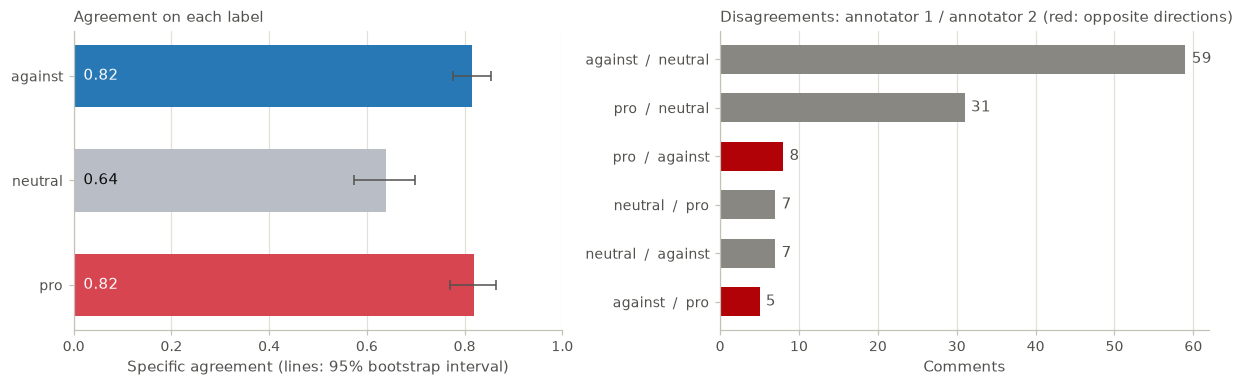

In [10]:
# specific agreement: of all the times either annotator used a label, the share where the other one used it too
def specific(m):
    return 2 * np.diag(m) / (m.sum(axis=1) + m.sum(axis=0))

spec = pd.Series(specific(m_all), index=CLASSES)
spec_boot = np.array([specific(confusion(codes[r])) for r in rng.integers(0, len(codes), size=(N_BOOT, len(codes)))])
spec_low, spec_high = np.quantile(spec_boot, [0.025, 0.975], axis=0)

# disagreements by direction: which label each annotator chose
off = pd.DataFrame([(CLASSES[i], CLASSES[j], m_all[i, j]) for i in range(3) for j in range(3) if i != j],
                   columns=["annotator_1", "annotator_2", "comments"]).sort_values("comments")

# Stuart-Maxwell test: do the two annotators use the three labels equally often?
diff = (m_all.sum(axis=1) - m_all.sum(axis=0))[:2]
cov = -(m_all + m_all.T)[:2, :2].astype(float)
np.fill_diagonal(cov, (m_all.sum(axis=1) + m_all.sum(axis=0) - 2 * np.diag(m_all))[:2])
chi2 = diff @ np.linalg.solve(cov, diff)
print(f"Stuart-Maxwell test of equal label use: chi2 = {chi2:.1f}, df = 2, p = {stats.chi2.sf(chi2, 2):.1g}")

fig, (ax_s, ax_o) = plt.subplots(1, 2, figsize=(11, 3.4), layout="constrained")
order = CLASSES[::-1]
ax_s.barh(order, spec[order], color=[LABEL_COLOR[c] for c in order], height=0.6)
ax_s.errorbar(spec[order], order, xerr=[(spec - spec_low)[order], (spec_high - spec)[order]],
              fmt="none", ecolor=INK_2, capsize=3, lw=1)
for y, c in enumerate(order):
    ax_s.text(0.02, y, f"{spec[c]:.2f}", va="center", fontsize=9.5, color=INK if c == "neutral" else "white")
ax_s.set_xlim(0, 1)
ax_s.grid(axis="y", visible=False)
ax_s.set_xlabel("Specific agreement (lines: 95% bootstrap interval)")
ax_s.set_title("Agreement on each label")

opposite_pair = ~off[["annotator_1", "annotator_2"]].eq("neutral").any(axis=1)
ax_o.barh([f"{a1}  /  {a2}" for a1, a2 in zip(off["annotator_1"], off["annotator_2"])], off["comments"],
          color=np.where(opposite_pair, "#B10207", MUTED), height=0.6)
for y, v in enumerate(off["comments"]):
    ax_o.text(v + 0.8, y, str(v), va="center", fontsize=9.5, color=INK_2)
ax_o.grid(axis="y", visible=False)
ax_o.set_xlabel("Comments")
ax_o.set_title("Disagreements: annotator 1 / annotator 2 (red: opposite directions)")
plt.show()

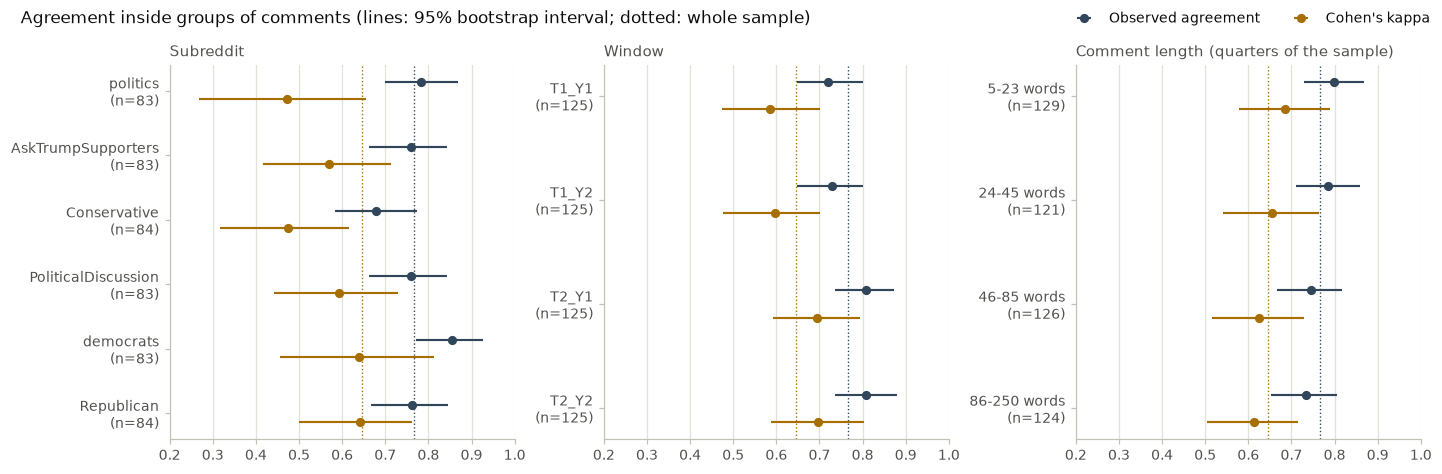

In [11]:
pairs["length"] = pd.qcut(pairs["words"], 4)
pairs["length"] = pairs["length"].cat.rename_categories(
    [f"{pairs['words'].min() if k == 0 else int(np.floor(iv.left)) + 1}-{int(iv.right)} words"
     for k, iv in enumerate(pairs["length"].cat.categories)])
GROUPS = {"subreddit": ("Subreddit", SUBREDDITS),
          "period": ("Window", PERIODS),
          "length": ("Comment length (quarters of the sample)", list(pairs["length"].cat.categories))}

rows = []
for column, (_, values) in GROUPS.items():
    for value in values:
        c = codes[(pairs[column] == value).to_numpy()]
        b = bootstrap(c, rng)
        for measure in ("agreement", "cohen_kappa"):
            rows.append({"group": column, "value": value, "measure": measure, "n": len(c),
                         "estimate": measures(confusion(c))[measure],
                         "low": b[measure].quantile(0.025), "high": b[measure].quantile(0.975)})
by_group = pd.DataFrame(rows)

MEASURE_STYLE = {"agreement": ("Observed agreement", "#31465A", 0.13), "cohen_kappa": ("Cohen's kappa", "#A66F00", -0.13)}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, layout="constrained")
for ax, (column, (title, values)) in zip(axes, GROUPS.items()):
    part = by_group[by_group["group"] == column]
    y = {v: len(values) - 1 - k for k, v in enumerate(values)}
    for measure, (label, color, shift) in MEASURE_STYLE.items():
        m = part[part["measure"] == measure]
        ax.errorbar(m["estimate"], m["value"].map(y) + shift, xerr=[m["estimate"] - m["low"], m["high"] - m["estimate"]],
                    fmt="o", color=color, ms=5, capsize=0, lw=1.4, label=label)
        ax.axvline(summary.loc[measure, "value"], color=color, lw=0.9, ls=":", zorder=0)
    n = part.drop_duplicates("value").set_index("value")["n"]
    ax.set_yticks(list(y.values()), [f"{v}\n(n={n[v]})" for v in y])
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0.2, 1)
    ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper right", ncols=2)
fig.suptitle("Agreement inside groups of comments (lines: 95% bootstrap interval; dotted: whole sample)", x=0.01, ha="left", fontsize=11)
plt.show()

The groups hold only 83 to 129 comments each, so the intervals are wide and most of them overlap with the whole-sample value. Observed agreement and Cohen's kappa can point in different directions. In r/politics most comments are `against` for both annotators, so chance agreement is already high and kappa comes out low even though observed agreement is close to the whole sample. In r/Conservative both measures are low, so there the annotators disagree more often in fact, not only after the correction for chance.

The comments below are the ones where one annotator saw support and the other saw opposition. They are the cases worth discussing together before the labels are used to judge the model.

In [12]:
opposite = pairs.loc[np.abs(codes[:, 0] - codes[:, 1]) == 2, ["subreddit", "period", "label_1", "label_2", "post_title", "comment"]]
with pd.option_context("display.max_colwidth", None):
    display(opposite.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))

,subreddit,period,label_1,label_2,post_title,comment
50,Republican,T2_Y2,pro,against,The Iranian Regime May Have Already Been Decapitated,So thats two wars that Trump has won in a combined half a day? Great record.
158,AskTrumpSupporters,T2_Y2,against,pro,What do you think of Trump's threat to impose tolls on the Straight of Hormuz?,Love Trump but getting tired of this Mickey Mouse shit. Either go in and whip their ass once and for all or leave. And he needs to keep his mouth shut.
163,Republican,T1_Y2,pro,against,MSNBC Guest Predicts Trump Reelected in Landslide If He Isn't Removed From Office,"I cant stand Trump. Still, I look forward to an over flowing tumbler of leftist tears on election night 2020"
197,Conservative,T1_Y1,against,pro,Republicans Sweep All Four of Their Special Elections,"It is always good to see republicans getting elected. After 8 years of Obama almost anyone seems conservative but true conservatives should be aware that Trump is not conservative. We have to be careful not to support the non-conservative things Trump does and says just because he has the (R) by his name. For example, he is completely wrong on trade and we should be skeptical of his trade talk. Same on healthcare. The supreme court was awesome, the EPA is amazing and he is dealing with ISIS pretty well. We cannot sacrifice principles because Trump was the only republican to actually stand up to the democrats."
211,Conservative,T1_Y2,pro,against,South Korea's Moon: Trump Should Win the Nobel Peace Prize,"Trump: *Hey Barrack, looks like we're Nobel Peace Prize buddies!* Obama: *looks like it* Trump: *I got mine by bringing peace to the Korean peninsula, what about you Barrack?* Obama: *I still don't know....* Trump: *Bob Mercer says it was cause you were black and in the white house Barrack* Obama: ..... Trump: ....."
220,AskTrumpSupporters,T2_Y1,against,pro,What is the biggest point you disagree with Trump on?,"I mostly have issues with his lack of commitment to aggressively pursuing gun rights and abortion bans. For all that the left freaks the fuck out about these two things, Trump is way more moderate than I think he could and should be."
278,politics,T1_Y2,against,pro,Sally Yates: If Trump doesn’t talk to Mueller he doesn’t have ‘moral authority to lead’,"Let's remove some words. ""~~If~~ Trump doesn’t ~~talk to Mueller he doesn’t~~ have moral authority ~~to lead~~""."
360,Conservative,T1_Y1,pro,against,The Silent Coup Against President Trump Extends to the Judiciary: 'Judges are Democrat hacks. They’re Democrat activists that wear robes.',"Yeah, Trump doesn't already know that! /s"
375,Conservative,T2_Y2,pro,against,Tillis: I Won't Support Any AG Nominee Who Thinks January 6 Was Excusable,"Between this douche, Massey, Paul, McConnell the Dems don’t even need to sweep midterms as they Already have a majority. Surprised they don’t launch impeachment hearings now as these traitors would be front and center trying to convict Trump. Un fucking believable."
414,democrats,T1_Y2,pro,against,Paul Krugman: Trump's Infrastructure Plan Was a Always a Scam. The celebrity mogul has never had any interest in serving the public.,"Fox News is a minor input to my news. I think. I have an MBA and MD. I have worked around the world. I have a moral code. Trump isn’t my choice for president, but the alternative was worse."


### 3.4 Review of the disagreements

Every comment with two different labels gets one final label. The disagreements are split between the two of us: the comments are sorted by the kind of disagreement (for example `against / neutral`) and given to reviewer 1 and reviewer 2 in turn, so each of us gets half of every kind. The split is computed from the two label files, so it is the same on both computers as long as both files are the same.

The cell shows the post and the comment as in section 3.2, and under them the label of each annotator. The final label can be either of them or the third one. The rules of section 3.2 apply. `s` marks a comment that cannot be judged; it is left out of the final labels.

Every decision is saved at once to `data/top_comments/review_reviewer1.csv` or `review_reviewer2.csv`, with the same controls as in section 3.2 (`b` back, `q` stop, running the cell again continues). To build the final labels, both review files have to be on the same computer.

In [13]:
FINAL_PATH = LABEL_DIR / "labels_final.csv"


def review_path(reviewer):
    return LABEL_DIR / f"review_reviewer{reviewer}.csv"


disagreements = pairs.loc[pairs["label_1"] != pairs["label_2"]].copy()
disagreements["kind"] = [" / ".join(sorted(p)) for p in zip(disagreements["label_1"], disagreements["label_2"])]
# alternating over the comments sorted by kind gives each reviewer half of every kind of disagreement
disagreements = disagreements.sort_values(["kind", "order"])
disagreements["reviewer"] = np.arange(len(disagreements)) % 2 + 1
display(pd.crosstab(disagreements["kind"], disagreements["reviewer"], margins=True)
        .rename_axis(index="labels of the two annotators", columns="reviewer"))


def load_review(reviewer, ids):
    path = review_path(reviewer)
    if not path.exists():
        return {}
    saved = pd.read_csv(path, dtype=str)
    stale = set(saved["id"]) - set(ids)
    assert not stale, f"{path.name} has {len(stale)} comments that are not among this reviewer's disagreements; were the labels changed?"
    return dict(saved[["id", "final"]].to_numpy())


def save_review(reviewer, done):
    path = review_path(reviewer)
    tmp = path.with_suffix(".tmp")
    pd.DataFrame(list(done.items()), columns=["id", "final"]).to_csv(tmp, index=False, lineterminator="\n")
    tmp.replace(path)


def review(reviewer):
    """Show this reviewer's half of the disagreements with both labels and ask for the final one. Saved after every comment."""
    rows = disagreements[disagreements["reviewer"] == reviewer].sort_values("order").reset_index(drop=True)
    done = load_review(reviewer, rows["id"])
    i = next((k for k, comment_id in enumerate(rows["id"]) if comment_id not in done), len(rows))
    try:
        while i < len(rows):
            row = rows.loc[i]
            show(row, f"Reviewer {reviewer} | disagreement {i + 1} of {len(rows)} | {len(done)} decided")
            print("\n" + "-" * LINE_WIDTH)
            print(f"Annotator 1: {row['label_1']}    Annotator 2: {row['label_2']}")
            current = f" (now: {done[row['id']]}, Enter keeps it)" if row["id"] in done else ""
            answer = input(f"\nFinal label: [a] against  [n] neutral  [p] pro  [s] skip  [b] back  [q] stop{current} > ").strip().lower()
            if answer == "q":
                break
            if answer == "b":
                i = max(i - 1, 0)
            elif answer in KEYS:
                done[row["id"]] = KEYS[answer]
                save_review(reviewer, done)
                i += 1
            elif answer == "" and current:
                i += 1
    except (StdinNotImplementedError, KeyboardInterrupt):
        pass                                                   # no keyboard input (for example during an export)
    clear_output(wait=True)
    print(f"Reviewer {reviewer}: {len(done)} of {len(rows)} disagreements are decided"
          + ("" if len(done) == len(rows) else "; run this cell to continue"))

reviewer,1,2,All
labels of the two annotators,,,
against / neutral,33,33,66
against / pro,7,6,13
neutral / pro,19,19,38
All,59,58,117


**Reviewer 1**

In [ ]:
# review(reviewer=1)

**Reviewer 2**

In [ ]:
# review(reviewer=2)

Reviewer 2: 58 of 58 disagreements are decided


**Final labels.** When both reviews are complete, the cell below joins them with the comments where the annotators agreed and saves `data/top_comments/labels_final.csv`. It also shows how often the final decision kept the label of annotator 1, of annotator 2, or neither.

In [16]:
decisions = {}
for r in (1, 2):
    if review_path(r).exists():
        decisions.update(dict(pd.read_csv(review_path(r), dtype=str)[["id", "final"]].to_numpy()))
missing = set(disagreements["id"]) - set(decisions)

final = pairs[["id", "subreddit", "period", "label_1", "label_2"]].copy()
agreed = final["label_1"] == final["label_2"]
final["label"] = final["label_1"].where(agreed, final["id"].map(decisions))
final["source"] = np.where(agreed, "both annotators", "review")

if missing:
    print(f"{len(missing)} of {len(disagreements)} disagreements still have no decision; run the review cells above")
else:
    skipped_in_review = final["label"].eq("skip")
    final.loc[~skipped_in_review, ["id", "label", "source"]].to_csv(FINAL_PATH, index=False, lineterminator="\n")
    print(f"Final labels saved to {FINAL_PATH.name}: {(~skipped_in_review).sum()} comments "
          f"({skipped_in_review.sum()} skipped in the review are left out)")
    reviewed = final.loc[~agreed]
    sided = pd.Series(np.select([reviewed["label"] == reviewed["label_1"], reviewed["label"] == reviewed["label_2"]],
                                ["annotator 1", "annotator 2"], "neither"), index=reviewed.index)
    display(pd.crosstab(sided, reviewed["label_1"] + " / " + reviewed["label_2"], margins=True)
            .rename_axis(index="final label agrees with", columns="annotator 1 / annotator 2"))
    display(final.loc[~skipped_in_review, "label"].value_counts().reindex(CLASSES, fill_value=0).to_frame("comments"))

Final labels saved to labels_final.csv: 500 comments (0 skipped in the review are left out)


annotator 1 / annotator 2,against / neutral,against / pro,neutral / against,neutral / pro,pro / against,pro / neutral,All
final label agrees with,,,,,,,
annotator 1,26,4,1,6,1,8,46
annotator 2,32,1,6,1,5,23,68
neither,1,0,0,0,2,0,3
All,59,5,7,7,8,31,117


,comments
label,
against,216
neutral,156
pro,128


### 3.5 Final labels

The final labels are the reference for the rest of this notebook: the label both annotators agreed on, or the decision of the review for the other comments. They are used for three things:

- what the comments in the sample say about Trump, by subreddit and by window;
- how well the student model (`student_label`) reproduces them, measured with the same statistics as the agreement between the annotators in section 3.3;
- whether the model reproduces the change between the two terms, which is the quantity the main report relies on.

The sample has the same number of comments in every subreddit and window (section 3.1). The shares below are therefore shares of this sample, not of Reddit: r/politics, which gives most of the comments in the full data, has the same weight here as r/Republican. The comparison of windows is still fair, because every window has the same mix of subreddits.

500 comments with a final label: 383 agreed by both annotators, 117 decided in the review


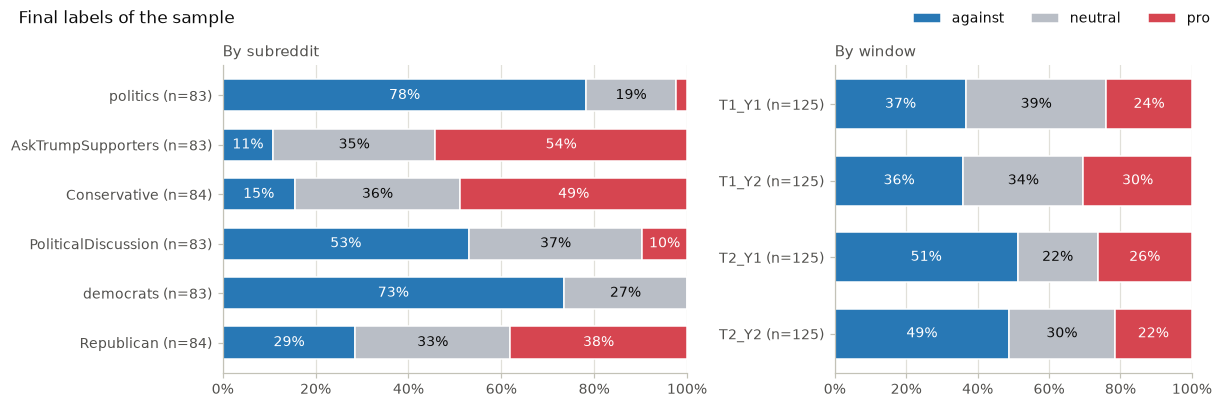

In [17]:
gold = pairs.merge(pd.read_csv(FINAL_PATH, dtype=str).rename(columns={"label": "final"}), on="id", validate="one_to_one")
gold = gold.merge(com[["id", "student_label"]].rename(columns={"student_label": "model"}), on="id", how="left", validate="one_to_one")
assert gold["model"].notna().all(), "some sampled comments have no student_label"
gold["term"] = gold["period"].str[:2]
print(f"{len(gold)} comments with a final label: {(gold['source'] == 'both annotators').sum()} agreed by both annotators, "
      f"{(gold['source'] == 'review').sum()} decided in the review")


def stacked_shares(ax, labels, groups, order, title):
    """Horizontal bars with the share of each label in every group, first group on top."""
    shares = pd.crosstab(groups, labels, normalize="index").reindex(index=order, columns=CLASSES, fill_value=0)
    n = groups.value_counts()
    y = np.arange(len(order))[::-1]
    left = np.zeros(len(order))
    for label in CLASSES:
        share = shares[label].to_numpy()
        ax.barh(y, share, left=left, height=0.65, color=LABEL_COLOR[label], edgecolor="white", label=label)
        for yy, s, l in zip(y, share, left):
            if s >= 0.06:
                ax.text(l + s / 2, yy, f"{s:.0%}", ha="center", va="center", fontsize=9, color=INK if label == "neutral" else "white")
        left += share
    ax.set_yticks(y, [f"{g} (n={n[g]})" for g in order])
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1))
    ax.grid(axis="y", visible=False)
    ax.set_title(title)


fig, (ax_s, ax_p) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]}, layout="constrained")
stacked_shares(ax_s, gold["final"], gold["subreddit"], SUBREDDITS, "By subreddit")
stacked_shares(ax_p, gold["final"], gold["period"], PERIODS, "By window")
fig.legend(*ax_s.get_legend_handles_labels(), loc="outside upper right", ncols=3)
fig.suptitle("Final labels of the sample", x=0.01, ha="left", fontsize=11)
plt.show()

The subreddits fall into two groups. In r/politics and r/democrats about three quarters of the comments are `against` and almost none are `pro` (2 of 166). In r/AskTrumpSupporters and r/Conservative about half are `pro` and only 11% and 15% are `against`. r/PoliticalDiscussion leans `against`, and r/Republican is the most mixed, with each label close to a third. From 19% to 37% of the comments in a subreddit are `neutral`.

Across the windows, the share of `against` rises from about 36% in both years of the first term to about 50% in both years of the second, mostly at the cost of `neutral`. The share of `pro` stays between 22% and 30%.